In [1]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
import pyspark.sql.types as T

In [2]:
spark = (
    SparkSession
        .builder
        .appName('Recipes ML model - Are you a dessert?')
        .config("spark.driver.memory", "8g")
        .getOrCreate()
)

spark.sparkContext

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/usr/local/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/24 15:52:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


<SparkContext master=local[*] appName=Recipes ML model - Are you a dessert?>

# **Setting the stage: Preparing features for machine learning**

## **Reading, exploring, and preparing our ML data set**

In [3]:
food = spark.read.csv(
    "../data/recipes/epi_r.csv", inferSchema=True, header=True
)

In [4]:
print(f"Rows => {food.count()}, Cols => {len(food.columns)}")

Rows => 20057, Cols => 680


In [5]:
food.printSchema()

root
 |-- title: string (nullable = true)
 |-- rating: string (nullable = true)
 |-- calories: string (nullable = true)
 |-- protein: double (nullable = true)
 |-- fat: double (nullable = true)
 |-- sodium: double (nullable = true)
 |-- #cakeweek: double (nullable = true)
 |-- #wasteless: double (nullable = true)
 |-- 22-minute meals: double (nullable = true)
 |-- 3-ingredient recipes: double (nullable = true)
 |-- 30 days of groceries: double (nullable = true)
 |-- advance prep required: double (nullable = true)
 |-- alabama: double (nullable = true)
 |-- alaska: double (nullable = true)
 |-- alcoholic: double (nullable = true)
 |-- almond: double (nullable = true)
 |-- amaretto: double (nullable = true)
 |-- anchovy: double (nullable = true)
 |-- anise: double (nullable = true)
 |-- anniversary: double (nullable = true)
 |-- anthony bourdain: double (nullable = true)
 |-- aperitif: double (nullable = true)
 |-- appetizer: double (nullable = true)
 |-- apple: double (nullable = true)


In [6]:
def sanitize_columns_name(name):
    """
    Drops unwanted characters from the column name.
    We replace spaces, dashes and slashes with underscore,
    and only keep alphanumeric characters.
    """
    answer = name
    for i, j in ((" ", "_"), ("-", "_"), ("/", "_"), ("&", "and")):
        answer = answer.replace(i, j)
    return "".join(
        [
            char
            for char in answer
            if char.isalpha() or char.isdigit() or char == "_"
        ]
    )

In [7]:
food = food.toDF(*[sanitize_columns_name(col) for col in food.columns])

In [8]:
#for col in food.columns:
#    food.select(col).summary().show()

![](../images/decision_tree_Feature.png)

In [9]:
import pandas as pd

In [10]:
is_binary = food.agg(
    *[
        (F.size(F.collect_set(col)) == 2).alias(col)
        for col in food.columns
    ]
).toPandas()

/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/24 15:53:07 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

In [11]:
is_binary.unstack()

title       0    False
rating      0    False
calories    0    False
protein     0    False
fat         0    False
                 ...  
cookbooks   0     True
leftovers   0     True
snack       0     True
snack_week  0     True
turkey      0     True
Length: 680, dtype: bool

In [12]:
is_binary.T[ is_binary.T.iloc[:, 0] == True].shape[0]

672

In [13]:
food.agg(*[F.collect_set(col) for col in ("cakeweek", "wasteless")]).show(1, False)

+-------------------------------+----------------------+
|collect_set(cakeweek)          |collect_set(wasteless)|
+-------------------------------+----------------------+
|[0.0, 1.0, 1188.0, 24.0, 880.0]|[0.0, 1.0, 1439.0]    |
+-------------------------------+----------------------+



In [14]:
food.where(
    "cakeweek > 1.0 or wasteless > 1.0"
).select(
    "title", "rating", "wasteless", "cakeweek", food.columns[-1]
).show()

+--------------------+--------------------+---------+--------+------+
|               title|              rating|wasteless|cakeweek|turkey|
+--------------------+--------------------+---------+--------+------+
|"Beet Ravioli wit...| Aged Balsamic Vi...|      0.0|   880.0|   0.0|
|"Seafood ""Catapl...|            Vermouth|   1439.0|    24.0|   0.0|
|"""Pot Roast"" of...| Aunt Gloria-Style "|      0.0|  1188.0|   0.0|
+--------------------+--------------------+---------+--------+------+



In [15]:
food = food.where(
    (
        F.col("cakeweek").isin([0.0, 1.0]) | F.col("cakeweek").isNull()
    )
    & (
        F.col('wasteless').isin([0.0, 1.0]) | F.col('wasteless').isNull()
    )
)

In [16]:
print(food.count(), len(food.columns))

20054 680


In [17]:
IDENTIFIERS = ["title"]

CONTINUOUS_COLUMNS = [
    "rating",
    "calories",
    "protein",
    "fat",
    "sodium",
]

TARGET_COLUMN = ["dessert"]

BINARY_COLUMNS = [
    x
    for x in food.columns
    if x not in CONTINUOUS_COLUMNS
    and x not in TARGET_COLUMN
    and x not in IDENTIFIERS
]

In [18]:
len(BINARY_COLUMNS)

673

In [19]:
food = food.dropna(
    how='all', subset=[x for x in food.columns if x not in IDENTIFIERS]
)

food = food.dropna(subset=TARGET_COLUMN)

In [20]:
food.count(), len(food.columns)

(20049, 680)

In [21]:
food = food.fillna(0.0, subset=BINARY_COLUMNS)

In [22]:
food.where(F.col(BINARY_COLUMNS[0]).isNull()).count()

0

In [23]:
from typing import Optional

In [24]:
@F.udf(T.BooleanType())
def is_a_number(value: Optional[str]) -> bool:
    if not value:
        return True
    try:
        _ = float(value)
    except ValueError:
        return False
    return True

/usr/local/lib/python3.12/site-packages/pyspark/sql/udf.py:116: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/typehints.py:60: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/site-packages/pyspark/sql/udf.py:135: UserWarning: Cannot infer the eval type from type hints. 
  warnings.warn("Cannot infer the eval type from type hints. ", UserWarning)


In [25]:
food.where(~is_a_number(F.col('rating'))).select(
    *CONTINUOUS_COLUMNS
).show()

[Stage 22:===================>                                      (1 + 2) / 3]

+---------+------------+-------+----+------+
|   rating|    calories|protein| fat|sodium|
+---------+------------+-------+----+------+
| Cucumber| and Lemon "|   3.75|NULL|  NULL|
+---------+------------+-------+----+------+



In [26]:
for column in ["rating", "calories"]:
    food = (
        food.withColumn(column, F.expr(f"try_cast(`{column}` AS DOUBLE)"))
        .filter(F.col(column).isNotNull())
    )

In [27]:
food.count(), len(food.columns)

(15932, 680)

In [28]:
food.select(CONTINUOUS_COLUMNS).summary(
   "mean",
    "stddev",
    "min",
    "1%",
    "5%",
    "50%",
    "95%",
    "99%",
    "max", 
).show()

[Stage 26:==============>                                           (1 + 3) / 4]

+-------+------------------+------------------+------------------+------------------+------------------+
|summary|            rating|          calories|           protein|               fat|            sodium|
+-------+------------------+------------------+------------------+------------------+------------------+
|   mean|3.7530206502636205|6324.0634571930705|100.17385283565179| 346.9398083953107| 6226.927244193346|
| stddev| 1.295794174959228| 359079.8369634017|3840.6809971287357|20458.040344124103|333349.56803702697|
|    min|               0.0|               0.0|               0.0|               0.0|               0.0|
|     1%|               0.0|              18.0|               0.0|               0.0|               1.0|
|     5%|               0.0|              62.0|               0.0|               0.0|               5.0|
|    50%|             4.375|             331.0|               8.0|              17.0|             294.0|
|    95%|               5.0|            1316.0|        

In [29]:
maximum = {
    "calories": 3203.0,
    "protein": 173.0,
    "fat": 207.0,
    "sodium": 5661.0,
}

for k, v in maximum.items():
    food = food.withColumn(
        k,
        F.when(F.isnull(F.col(k)), F.col(k)).otherwise(
            F.least(F.col(k), F.lit(v))
        )
    )

In [30]:
inst_sum_of_binary_columns = [
    F.sum(F.col(column)).alias(column) for column in BINARY_COLUMNS
]

inst_sum_of_binary_columns

[Column<'sum(cakeweek) AS cakeweek'>,
 Column<'sum(wasteless) AS wasteless'>,
 Column<'sum(22_minute_meals) AS 22_minute_meals'>,
 Column<'sum(3_ingredient_recipes) AS 3_ingredient_recipes'>,
 Column<'sum(30_days_of_groceries) AS 30_days_of_groceries'>,
 Column<'sum(advance_prep_required) AS advance_prep_required'>,
 Column<'sum(alabama) AS alabama'>,
 Column<'sum(alaska) AS alaska'>,
 Column<'sum(alcoholic) AS alcoholic'>,
 Column<'sum(almond) AS almond'>,
 Column<'sum(amaretto) AS amaretto'>,
 Column<'sum(anchovy) AS anchovy'>,
 Column<'sum(anise) AS anise'>,
 Column<'sum(anniversary) AS anniversary'>,
 Column<'sum(anthony_bourdain) AS anthony_bourdain'>,
 Column<'sum(aperitif) AS aperitif'>,
 Column<'sum(appetizer) AS appetizer'>,
 Column<'sum(apple) AS apple'>,
 Column<'sum(apple_juice) AS apple_juice'>,
 Column<'sum(apricot) AS apricot'>,
 Column<'sum(arizona) AS arizona'>,
 Column<'sum(artichoke) AS artichoke'>,
 Column<'sum(arugula) AS arugula'>,
 Column<'sum(asian_pear) AS asia

In [31]:
sum_of_binary_columns = (
    food.select(inst_sum_of_binary_columns).head().asDict()
)

sum_of_binary_columns

26/11/24 15:53:21 WARN DAGScheduler: Broadcasting large task binary with size 1638.9 KiB
                                                                                

{'cakeweek': 6.0,
 'wasteless': 1.0,
 '22_minute_meals': 15.0,
 '3_ingredient_recipes': 20.0,
 '30_days_of_groceries': 7.0,
 'advance_prep_required': 73.0,
 'alabama': 1.0,
 'alaska': 2.0,
 'alcoholic': 621.0,
 'almond': 477.0,
 'amaretto': 32.0,
 'anchovy': 27.0,
 'anise': 90.0,
 'anniversary': 89.0,
 'anthony_bourdain': 2.0,
 'aperitif': 6.0,
 'appetizer': 1047.0,
 'apple': 544.0,
 'apple_juice': 5.0,
 'apricot': 222.0,
 'arizona': 8.0,
 'artichoke': 123.0,
 'arugula': 199.0,
 'asian_pear': 14.0,
 'asparagus': 157.0,
 'aspen': 1.0,
 'atlanta': 5.0,
 'australia': 5.0,
 'avocado': 206.0,
 'back_to_school': 152.0,
 'backyard_bbq': 685.0,
 'bacon': 504.0,
 'bake': 3725.0,
 'banana': 126.0,
 'barley': 39.0,
 'basil': 449.0,
 'bass': 61.0,
 'bastille_day': 21.0,
 'bean': 427.0,
 'beef': 669.0,
 'beef_rib': 48.0,
 'beef_shank': 10.0,
 'beef_tenderloin': 60.0,
 'beer': 78.0,
 'beet': 152.0,
 'bell_pepper': 574.0,
 'berry': 350.0,
 'beverly_hills': 1.0,
 'birthday': 150.0,
 'biscuit': 4.0,
 '

In [32]:
num_rows = food.count()
too_rare_features = [
    k
    for k, v in sum_of_binary_columns.items()
    if v < 10 or v > (num_rows - 10)
]

len(too_rare_features)

183

In [33]:
BINARY_COLUMNS = list(set(BINARY_COLUMNS) - set(too_rare_features))

len(BINARY_COLUMNS)

490

## **Feature creation and refinement**

In [34]:
food = food.withColumn(
    "protein_ratio", F.try_divide(F.col('protein') * 4, F.col('calories'))
).withColumn(
    'fat_ratio', F.try_divide(F.col("fat") * 9, F.col('calories'))
)

food = food.fillna(0.0, subset=['protein_ratio', 'fat_ratio'])

CONTINUOUS_COLUMNS += ['protein_ratio', 'fat_ratio']

In [35]:
from pyspark.ml.feature import VectorAssembler

In [36]:
continuous_features = VectorAssembler(
    inputCols=CONTINUOUS_COLUMNS, outputCol="continuous_features"
)

vector_food = food.select(CONTINUOUS_COLUMNS)

for x in CONTINUOUS_COLUMNS:
    vector_food = vector_food.where(~F.isnull(F.col(x)))

vector_variable = continuous_features.transform(vector_food)

vector_variable.select("continuous_features").show(3, False)

+---------------------------------------------------------------------+
|continuous_features                                                  |
+---------------------------------------------------------------------+
|[2.5,426.0,30.0,7.0,559.0,0.28169014084507044,0.14788732394366197]   |
|[4.375,403.0,18.0,23.0,1439.0,0.17866004962779156,0.5136476426799007]|
|[3.75,165.0,6.0,7.0,165.0,0.14545454545454545,0.38181818181818183]   |
+---------------------------------------------------------------------+
only showing top 3 rows


In [37]:
vector_variable.select('continuous_features').printSchema()

root
 |-- continuous_features: vector (nullable = true)



In [38]:
from pyspark.ml.stat import Correlation

In [39]:
correlation = Correlation.corr(
    vector_variable, 'continuous_features'
)

correlation.printSchema()

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


root
 |-- pearson(continuous_features): matrix (nullable = false)



In [40]:
correlation.toPandas()

/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,pearson(continuous_features)
0,"DenseMatrix([[1. , 0.10225725, 0.113291..."


In [41]:
correlation_array = correlation.head()[0].toArray()

correlation_array

array([[1.        , 0.10225725, 0.11329165, 0.11153614, 0.06522544,
        0.0944287 , 0.12994604],
       [0.10225725, 1.        , 0.75783697, 0.91805212, 0.51681827,
        0.16473473, 0.1768231 ],
       [0.11329165, 0.75783697, 1.        , 0.6648986 , 0.58544983,
        0.6001825 , 0.1091883 ],
       [0.11153614, 0.91805212, 0.6648986 , 1.        , 0.42191991,
        0.12557241, 0.42498562],
       [0.06522544, 0.51681827, 0.58544983, 0.42191991, 1.        ,
        0.33906663, 0.03381897],
       [0.0944287 , 0.16473473, 0.6001825 , 0.12557241, 0.33906663,
        1.        , 0.0248537 ],
       [0.12994604, 0.1768231 , 0.1091883 , 0.42498562, 0.03381897,
        0.0248537 , 1.        ]])

In [42]:
correlation_pd = pd.DataFrame(
    correlation_array, index=CONTINUOUS_COLUMNS, columns=CONTINUOUS_COLUMNS
)

correlation_pd

,rating,calories,protein,fat,sodium,protein_ratio,fat_ratio
rating,1.000000,0.102257,0.113292,0.111536,0.065225,0.094429,0.129946
calories,0.102257,1.000000,0.757837,0.918052,0.516818,0.164735,0.176823
protein,0.113292,0.757837,1.000000,0.664899,0.585450,0.600182,0.109188
fat,0.111536,0.918052,0.664899,1.000000,0.421920,0.125572,0.424986
sodium,0.065225,0.516818,0.585450,0.421920,1.000000,0.339067,0.033819
protein_ratio,0.094429,0.164735,0.600182,0.125572,0.339067,1.000000,0.024854
fat_ratio,0.129946,0.176823,0.109188,0.424986,0.033819,0.024854,1.000000


## **Feature preparation with transformers and estimators**

![](../images/The_Transformer.png)

![](../images/The_Estimator.png)

In [43]:
from pyspark.ml.feature import Imputer

In [44]:
OLD_COLS = ["calories", "protein", "fat", "sodium"]
NEW_COLS = ["calories_i", "protein_i", "fat_i", "sodium_i"]

imputer = Imputer(
    strategy="mean",
    inputCols=OLD_COLS,
    outputCols=NEW_COLS
)

imputer_model = imputer.fit(food)

CONTINUOUS_COLUMNS = (
    list(set(CONTINUOUS_COLUMNS) - set(OLD_COLS)) + NEW_COLS
)

In [47]:
food_imputed = imputer_model.transform(food)

food_imputed.where(F.isnull(F.col('calories'))).select("calories", "calories_i").show(5, False)

+--------+----------+
|calories|calories_i|
+--------+----------+
+--------+----------+



![](../images/MinMaxScalerModel.png)

In [48]:
from pyspark.ml.feature import MinMaxScaler

In [53]:
CONTINUOUS_NB = [x for x in CONTINUOUS_COLUMNS if 'ratio' not in x]

continuous_assembler = VectorAssembler(
    inputCols=CONTINUOUS_NB, outputCol="continuous"
)

food_features = continuous_assembler.transform(food_imputed)

continuous_scaler = MinMaxScaler(
    inputCol='continuous',
    outputCol='continuous_scaled'
)

food_features = continuous_scaler.fit(food_features).transform(
    food_features
)

food_features.select("continuous_scaled").show(3, False)

+-----------------------------------------------------------------------------------------+
|continuous_scaled                                                                        |
+-----------------------------------------------------------------------------------------+
|[0.5,0.13300031220730565,0.17341040462427745,0.033816425120772944,0.09874580462815757]   |
|[0.875,0.12581954417733376,0.10404624277456646,0.1111111111111111,0.2541953718424307]    |
|[0.75,0.051514205432407124,0.03468208092485549,0.033816425120772944,0.029146793852676208]|
+-----------------------------------------------------------------------------------------+
only showing top 3 rows


# **Robust machine learning with ML Pipelines**

## **Transformers and estimators: The building blocks of ML in Spark**

In [59]:
CONTINUOUS_NB = ["rating", "calories_i", "protein_i", "fat_i", "sodium_i"]

continuous_assembler = VectorAssembler(
    inputCols=CONTINUOUS_NB, outputCol="continuous"
)

continuous_scaler = MinMaxScaler(
    inputCol="continuous",
    outputCol="continuous_scaled",
)

![](../images/continuous_assembler_Transformer.png)

In [60]:
continuous_assembler.outputCol

Param(parent='VectorAssembler_314f0a603289', name='outputCol', doc='output column name.')

In [63]:
continuous_assembler.getOutputCol(), continuous_assembler.getInputCols()

('continuous', ['rating', 'calories_i', 'protein_i', 'fat_i', 'sodium_i'])

In [64]:
continuous_assembler.explainParam('outputCol')

'outputCol: output column name. (default: VectorAssembler_314f0a603289__output, current: continuous)'

In [65]:
continuous_assembler.setOutputCol('more_continuous')

continuous_assembler.getOutputCol()

'more_continuous'

In [66]:
continuous_assembler.setParams(
    inputCols=["one", "two", "three"], handleInvalid="skip"
)

continuous_assembler.explainParams()

"handleInvalid: How to handle invalid data (NULL and NaN values). Options are 'skip' (filter out rows with invalid data), 'error' (throw an error), or 'keep' (return relevant number of NaN in the output). Column lengths are taken from the size of ML Attribute Group, which can be set using `VectorSizeHint` in a pipeline before `VectorAssembler`. Column lengths can also be inferred from first rows of the data since it is safe to do so but only in case of 'error' or 'skip'). (default: error, current: skip)\ninputCols: input column names. (current: ['one', 'two', 'three'])\noutputCol: output column name. (default: VectorAssembler_314f0a603289__output, current: more_continuous)"

In [67]:
continuous_assembler.clear(continuous_assembler.handleInvalid)

continuous_assembler.getHandleInvalid()

'error'

> When working with transformers (and estimators), remember that they are passed by reference and that setters modify the object in place. If you assign your transformer to a new variable name and then use a setter on either of those variables, it’ll modify the Param for both references. The solution to this is to copy() the transformer and then assign the copy to the new
variable.

![](../images/The_MinMaxScaler_Estimator.png)

## **Building a (complete) machine learning pipeline**

In [68]:
from pyspark.ml import Pipeline
import pyspark.ml.feature as MF

In [69]:
imputer = MF.Imputer(
    strategy="mean",
    inputCols=["calories", "protein", "fat", "sodium"],
    outputCols=["calories_i", "protein_i", "fat_i", "sodium_i"]
)

continuous_assembler = MF.VectorAssembler(
    inputCols=["rating", "calories_i", "protein_i", "fat_i", "sodium_i"],
    outputCol="continuous"
)

continuous_scaler = MF.MinMaxScaler(
    inputCol="continuous",
    outputCol="continuous_scaled"
)

food_pipeline = Pipeline(
    stages=[imputer, continuous_assembler, continuous_scaler]
)

![](../images/food_pipeline.png)

In [72]:
preml_assembler = MF.VectorAssembler(
    inputCols=BINARY_COLUMNS + ["continuous_scaled"] + ["protein_ratio", "fat_ratio"],
    outputCol="features"
)

food_pipeline.setStages(
    [imputer, continuous_assembler, continuous_scaler, preml_assembler]
)

food_pipeline_model = food_pipeline.fit(food)
food_feature = food_pipeline_model.transform(food)

- When storing vectors, PySpark has two choices for representing vectors:
    - A **dense representation**, where a Vector in PySpark is simply a NumPy (a high-performance multidimensional array library for Python) single-dimensional array object
    - A **sparse representation**, where a Vector in PySpark is an optimized sparse vector compatible with the SciPy (a scientific computing library in Python) scipy.sparse matrix

In [73]:
food_feature.select("title", "dessert", "features").show(5, truncate=30)

+------------------------------+-------+------------------------------+
|                         title|dessert|                      features|
+------------------------------+-------+------------------------------+
|Lentil, Apple, and Turkey W...|    0.0|(497,[85,99,100,138,165,279...|
|Boudin Blanc Terrine with R...|    0.0|(497,[11,41,50,95,112,162,1...|
| Potato and Fennel Soup Hodge |    0.0|(497,[82,85,86,126,149,294,...|
|     Spinach Noodle Casserole |    0.0|(497,[15,41,85,95,221,294,3...|
|                The Best Blts |    0.0|(497,[50,66,95,100,138,187,...|
+------------------------------+-------+------------------------------+
only showing top 5 rows


In [75]:
food_feature.schema['features']

StructField('features', VectorUDT(), True)

In [76]:
food_feature.schema['features'].metadata

{'ml_attr': {'num_attrs': 497,
  'attrs': {'numeric': [{'name': 'super_bowl', 'idx': 0},
    {'name': 'goose', 'idx': 1},
    {'name': 'picnic', 'idx': 2},
    {'name': 'portland', 'idx': 3},
    {'name': 'fontina', 'idx': 4},
    {'name': '3_ingredient_recipes', 'idx': 5},
    {'name': 'cheddar', 'idx': 6},
    {'name': 'beef_shank', 'idx': 7},
    {'name': 'seafood', 'idx': 8},
    {'name': 'chestnut', 'idx': 9},
    {'name': 'smoothie', 'idx': 10},
    {'name': 'port', 'idx': 11},
    {'name': 'cashew', 'idx': 12},
    {'name': 'low_no_sugar', 'idx': 13},
    {'name': 'hanukkah', 'idx': 14},
    {'name': 'side', 'idx': 15},
    {'name': 'chickpea', 'idx': 16},
    {'name': 'coconut', 'idx': 17},
    {'name': 'low_sugar', 'idx': 18},
    {'name': 'tree_nut', 'idx': 19},
    {'name': 'endive', 'idx': 20},
    {'name': 'champagne', 'idx': 21},
    {'name': 'oregano', 'idx': 22},
    {'name': 'pine_nut', 'idx': 23},
    {'name': 'pickles', 'idx': 24},
    {'name': 'wedding', 'idx': 25},

In [77]:
from pyspark.ml.classification import LogisticRegression

In [78]:
lr = LogisticRegression(
    featuresCol="features", labelCol="dessert", predictionCol="prediction"
)

food_pipeline.setStages(
    [
        imputer,
        continuous_assembler,
        continuous_scaler,
        preml_assembler,
        lr
    ]
)

Pipeline_825f79035322

In [79]:
train, test = food.randomSplit([0.7, 0.3], 13)

train.cache()

food_pipeline_model = food_pipeline.fit(train)
results = food_pipeline_model.transform(test)

In [80]:
results.select("prediction", "rawPrediction", "probability").show(3, False)

[Stage 302:>                                                        (0 + 1) / 1]

+----------+----------------------------------------+-----------------------------------------+
|prediction|rawPrediction                           |probability                              |
+----------+----------------------------------------+-----------------------------------------+
|0.0       |[19.99957807578147,-19.99957807578147]  |[0.9999999979379766,2.062023440885241E-9]|
|0.0       |[44.76969539509281,-44.76969539509281]  |[1.0,0.0]                                |
|0.0       |[12.427796737304257,-12.427796737304257]|[0.9999959943341756,4.005665824369231E-6]|
+----------+----------------------------------------+-----------------------------------------+
only showing top 3 rows


## **Evaluating and optimizing our model**

![](../images/confusion_matrix.png)

In [84]:
results.groupby('dessert').pivot('prediction').count().show()

26/11/24 19:00:35 WARN DAGScheduler: Broadcasting large task binary with size 1103.9 KiB
26/11/24 19:00:36 WARN DAGScheduler: Broadcasting large task binary with size 1103.6 KiB
26/11/24 19:00:36 WARN DAGScheduler: Broadcasting large task binary with size 1099.7 KiB
[Stage 327:>                                                        (0 + 4) / 4]

+-------+----+---+
|dessert| 0.0|1.0|
+-------+----+---+
|    0.0|3846| 74|
|    1.0|  76|823|
+-------+----+---+



26/11/24 19:00:37 WARN DAGScheduler: Broadcasting large task binary with size 1111.5 KiB
26/11/24 19:00:37 WARN DAGScheduler: Broadcasting large task binary with size 1115.6 KiB
                                                                                

In [85]:
from pyspark.mllib.evaluation import MulticlassMetrics

In [88]:
results_rdd = (
    results
    .select("prediction", "dessert")
    .rdd
    .map(lambda row: (float(row["prediction"]), float(row["dessert"])))
)

metrics = MulticlassMetrics(results_rdd)
cm = metrics.confusionMatrix().toArray()

cm

/usr/local/lib/python3.12/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
                                                                                

array([[3846.,   74.],
       [  76.,  823.]])

In [104]:
results_rdd.collect()

[(0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (1.0, 0.0),
 (1.0, 1.0),
 (0.0, 1.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (0.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 0.0),
 (0.0, 0.0),
 (0.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),

In [105]:
lr_model = food_pipeline_model.stages[-1]
metrics = lr_model.evaluate(results.select("title", "dessert", "features"))

print(f"Model precision: {metrics.precisionByLabel[1]}")
print(f"Model recall: {metrics.recallByLabel[1]}")

Model precision: 0.9175027870680045
Model recall: 0.9154616240266963


In [106]:
predictionAndLabel = results.select("prediction", "dessert").rdd
metrics_rdd = MulticlassMetrics(predictionAndLabel)

print(f"Model precision: {metrics_rdd.precision(1.0)}")
print(f"Model recall: {metrics_rdd.recall(1.0)}")

/usr/local/lib/python3.12/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
[Stage 351:==============>                                          (1 + 3) / 4]

Model precision: 0.9175027870680045
Model recall: 0.9154616240266963


![](../images/ROC_curve.png)

In [107]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

In [108]:
evaluator = BinaryClassificationEvaluator(
    labelCol='dessert',
    rawPredictionCol='rawPrediction',
    metricName='areaUnderROC'
)

accuracy = evaluator.evaluate(results)
print(f"Area under ROC = {accuracy} ")

Area under ROC = 0.9927680415881598 


In [109]:
import matplotlib.pyplot as plt

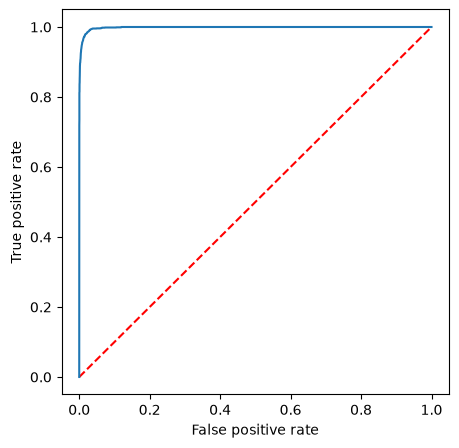

In [110]:
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "r--")
plt.plot(
    lr_model.summary.roc.select("FPR").collect(),
    lr_model.summary.roc.select("TPR").collect(),
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.show()

In [112]:
from pyspark.ml.tuning import ParamGridBuilder

In [113]:
grid_search = (
    ParamGridBuilder()
    .addGrid(lr.elasticNetParam, [0.0, 1.0])
    .build()
)

In [116]:
grid_search

[{Param(parent='LogisticRegression_51b2e02cc7b6', name='elasticNetParam', doc='the ElasticNet mixing parameter, in range [0, 1]. For alpha = 0, the penalty is an L2 penalty. For alpha = 1, it is an L1 penalty.'): 0.0},
 {Param(parent='LogisticRegression_51b2e02cc7b6', name='elasticNetParam', doc='the ElasticNet mixing parameter, in range [0, 1]. For alpha = 0, the penalty is an L2 penalty. For alpha = 1, it is an L1 penalty.'): 1.0}]

![](../images/Three-fold_cross-validation.png)

In [117]:
from pyspark.ml.tuning import CrossValidator

In [118]:
cv = CrossValidator(
    estimator=food_pipeline,
    estimatorParamMaps=grid_search,
    evaluator=evaluator,
    numFolds=3,
    seed=13,
    collectSubModels=True,
)

cv_model = cv.fit(train)

cv_model.avgMetrics

[np.float64(0.9883953243194532), np.float64(0.9883960038550322)]

In [119]:
pipeline_food_model = cv_model.bestModel

## **Getting the biggest drivers from our model: Extracting the coefficients**

In [120]:
import pandas as pd

In [123]:
feature_names = ["(Intercept)"] + [
    x["name"]
    for x in (
        food_feature
            .schema["features"]
            .metadata["ml_attr"]["attrs"]["numeric"]
    )
]

feature_names

['(Intercept)',
 'super_bowl',
 'goose',
 'picnic',
 'portland',
 'fontina',
 '3_ingredient_recipes',
 'cheddar',
 'beef_shank',
 'seafood',
 'chestnut',
 'smoothie',
 'port',
 'cashew',
 'low_no_sugar',
 'hanukkah',
 'side',
 'chickpea',
 'coconut',
 'low_sugar',
 'tree_nut',
 'endive',
 'champagne',
 'oregano',
 'pine_nut',
 'pickles',
 'wedding',
 'pernod',
 'vinegar',
 'rice',
 'leek',
 'plantain',
 'hominy_cornmeal_masa',
 'cream_cheese',
 'paleo',
 'marinate',
 'chile_pepper',
 'duck',
 'ice_cream_machine',
 'mustard_greens',
 'shrimp',
 'citrus',
 'bake',
 'cognac_armagnac',
 'fourth_of_july',
 '22_minute_meals',
 'kidney_friendly',
 'okra',
 'pear',
 'blender',
 'green_onion_scallion',
 'food_processor',
 'cardamom',
 'microwave',
 'chambord',
 'roast',
 'tree_nut_free',
 'watermelon',
 'tomatillo',
 'mothers_day',
 'pittsburgh',
 'braise',
 'low_carb',
 'oyster',
 'lobster',
 'parsley',
 'sugar_conscious',
 'summer',
 'st_patricks_day',
 'cantaloupe',
 'bread',
 'casserole_gra

In [124]:
feature_coefficients = [lr_model.intercept] + list(lr_model.coefficients.values)

feature_coefficients

[-2.4354647544850785,
 np.float64(-2.5365028183941756),
 np.float64(-6.191847527537118),
 np.float64(0.5117805290830943),
 np.float64(1.6132018953284057),
 np.float64(-7.196782129358733),
 np.float64(-1.4313215076974184),
 np.float64(0.3638295890509192),
 np.float64(1.2874386806203324),
 np.float64(-3.978418572710731),
 np.float64(-2.7177519996156616),
 np.float64(-1.5001449533644466),
 np.float64(-1.2949460602173382),
 np.float64(-2.3005242745237022),
 np.float64(-4.377583982672665),
 np.float64(-2.2267761379534843),
 np.float64(-6.809757413371017),
 np.float64(-6.76672564537953),
 np.float64(0.46612331493290754),
 np.float64(-19.19533169514169),
 np.float64(-0.47553017649637247),
 np.float64(-3.040230830850972),
 np.float64(-4.230258456247074),
 np.float64(-0.44019484111114565),
 np.float64(0.16768202206034338),
 np.float64(-10.12031555075859),
 np.float64(-1.5015726828726357),
 np.float64(6.211195772029933),
 np.float64(-2.346472003516487),
 np.float64(-0.1360398033721141),
 np.floa

In [125]:
coefficients = pd.DataFrame(
    feature_coefficients, 
    index=feature_names, 
    columns=["coef"]
)

coefficients["abs_coef"] = coefficients["coef"].abs()

coefficients.sort_values(["abs_coef"])

,coef,abs_coef
macadamia_nut,0.001566,0.001566
nut,0.003844,0.003844
mardi_gras,-0.011218,0.011218
ricotta,-0.031287,0.031287
ground_lamb,0.033352,0.033352
...,...,...
shavuot,18.048511,18.048511
sage,-18.527295,18.527295
low_sugar,-19.195332,19.195332
arugula,-20.862199,20.862199


In [126]:
pipeline_food_model.write().overwrite().save("../models/predictive_model_dessert")

In [127]:
from pyspark.ml.pipeline import PipelineModel

In [129]:
loaded_model = PipelineModel.load("../models/predictive_model_dessert")

# **Building custom ML transformers and estimators**